# 09 — Resultados y recomendaciones para el fondo

## Objetivo

Traducir los resultados en las dos decisiones del interlocutor:

1. **¿Qué propiedades visitar u ofertar?** Ranking de subvaluación.
2. **¿Conviene comprar y refaccionar una unidad puntual?** Modelo de flipping.

**Cambio respecto de la versión anterior.** La primera versión recomendaba
comprar unidades puntuales a partir del modelo económico con supuestos
ilustrativos. Con los supuestos con fuente (notebook 07), el flipping no resulta
rentable en general (H3, notebook 08). Por eso, la recomendación principal pasa
a ser el ranking de subvaluación confirmado por dos métodos, y el flipping se
usa como herramienta de oferta (precio máximo), no como lista de compras.

Fuentes: `remax_deptos_features.csv` (notebook 03),
`oportunidades_benchmark_ajustado.csv` (notebook 11) y
`flipping_ranking_priorizado.csv` (notebook 07).

In [1]:
# Entorno: ubicar la raíz del repositorio (la carpeta que contiene src/)
import os
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / "src").is_dir() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
os.chdir(RAIZ)
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import BASE_FEATURES, PROCESSED_DIR, DESCUENTO_NEGOCIABLE_PCT, MARGEN_MINIMO_PCT

sns.set_theme(style="whitegrid")
feat = pd.read_csv(BASE_FEATURES)
ajust = pd.read_csv(PROCESSED_DIR / "oportunidades_benchmark_ajustado.csv")
flip = pd.read_csv(PROCESSED_DIR / "flipping_ranking_priorizado.csv")
print("Avisos:", len(feat), "| con benchmark ajustado:", len(ajust), "| evaluados para flipping:", len(flip))

Avisos: 9499 | con benchmark ajustado: 9194 | evaluados para flipping: 428


## 1. Decisión 1 — Qué propiedades visitar

Se consideran **candidatas de mayor confianza** las propiedades que cumplen las
dos condiciones siguientes:

- son baratas según el benchmark jerárquico (gap ≥ 25 % y cuartil inferior del
  estrato) **y** según el benchmark ajustado por antigüedad y características
  (notebook 11);
- no tienen indicadores de posible error de carga (categoría `Barata`, no
  `Barata_requiere_verificacion`).

In [2]:
cols_feat = ["ID", "Clasificacion_Oportunidad", "Estado_Publicacion", "Precio_Valor",
             "Superficie_Homogeneizada_m2", "Ambientes", "Comuna", "Precio_Esperado",
             "N_Comparables", "Nivel_Benchmark", "Link", "Titulo"]
op = ajust.merge(feat[cols_feat], on="ID", how="left")

resumen = pd.crosstab(op["Categoria_Doble"], op["Clasificacion_Oportunidad"], margins=True)
display(resumen)

alta = op[op["Categoria_Doble"].eq("Confirmada_por_ambos") & op["Clasificacion_Oportunidad"].eq("Barata")].copy()
print("Candidatas de mayor confianza:", len(alta))

Clasificacion_Oportunidad,Barata,Barata_requiere_verificacion,Precio_de_mercado,All
Categoria_Doble,,,,
Confirmada_por_ambos,249,76,1,326
No_barata,0,0,7684,7684
Solo_benchmark,443,33,20,496
Solo_hedonico,0,0,271,271
All,692,109,7976,8777


Candidatas de mayor confianza: 249


**Evidencia de que la señal es real.** Si las baratas fueran solo errores o
avisos mal cargados, no deberían venderse más rápido que el resto. Se compara la
proporción de avisos reservados o en negociación.

In [3]:
op["Con_operacion"] = op["Estado_Publicacion"].isin(["reserved", "negotiation"])
op["Grupo"] = np.select(
    [op.index.isin(alta.index), op["Categoria_Doble"].ne("No_barata")],
    ["Confirmada por ambos (sin error)", "Barata por un solo método"], "No barata")
liq = (op.groupby("Grupo")["Con_operacion"].agg(["mean", "size"])
       .rename(columns={"mean": "% reservado o en negociación", "size": "Avisos"}))
liq["% reservado o en negociación"] = (liq["% reservado o en negociación"] * 100).round(1)
display(liq)

from scipy import stats
tabla = pd.crosstab(op["Grupo"].eq("Confirmada por ambos (sin error)"), op["Con_operacion"])
chi2, p, *_ = stats.chi2_contingency(tabla)
print(f"Chi-cuadrado confirmadas vs. resto: chi2 = {chi2:.1f}, p = {p:.1e}")

,% reservado o en negociación,Avisos
Grupo,,
Barata por un solo método,32.2,1261
Confirmada por ambos (sin error),40.6,249
No barata,23.0,7684


Chi-cuadrado confirmadas vs. resto: chi2 = 33.4, p = 7.5e-09


,Candidatas,Gap_mediano_pct,Precio_mediano_USD,% de la oferta del barrio
Barrio_Oficial,,,,
Palermo,20,29.3,129900.0,1.8
Recoleta,18,32.4,98000.0,2.9
Balvanera,17,30.8,90000.0,2.9
Caballito,17,31.4,106000.0,2.1
San Nicolas,15,32.6,79999.0,5.5
Almagro,13,27.9,79000.0,2.4
Flores,13,37.9,59000.0,3.1
Retiro,11,34.1,75000.0,5.2
Belgrano,10,32.0,190000.0,2.0


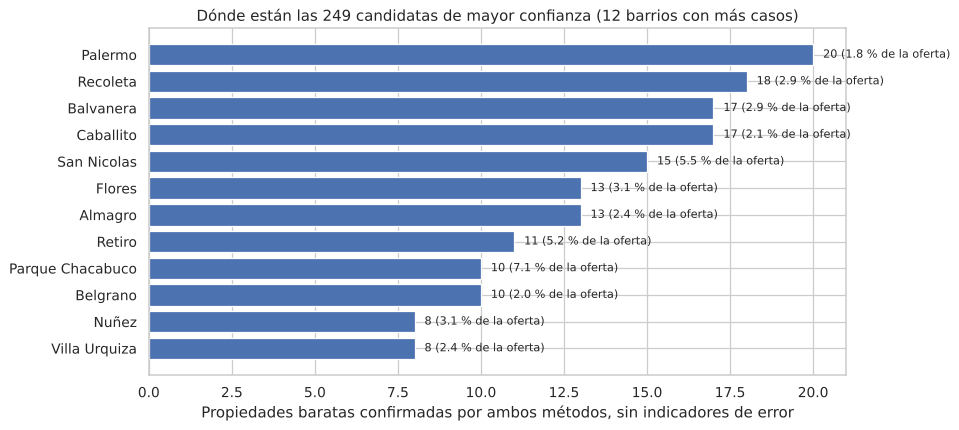

In [4]:
por_barrio = (alta.groupby("Barrio_Oficial")
              .agg(Candidatas=("ID", "size"), Gap_mediano_pct=("Gap_Hedonico_pct", "median"),
                   Precio_mediano_USD=("Precio_Valor", "median"))
              .sort_values("Candidatas", ascending=False))
total_barrio = op.groupby("Barrio_Oficial").size()
por_barrio["% de la oferta del barrio"] = (por_barrio["Candidatas"] / total_barrio.reindex(por_barrio.index) * 100).round(1)
display(por_barrio.head(12).round(1))

fig, ax = plt.subplots(figsize=(10, 5))
top = por_barrio.head(12).sort_values("Candidatas")
ax.barh(top.index, top["Candidatas"], color="#4C72B0")
for y, (n, pct) in enumerate(zip(top["Candidatas"], top["% de la oferta del barrio"])):
    ax.text(n + 0.3, y, f"{n} ({pct:.1f} % de la oferta)", va="center", fontsize=9)
ax.set(title=f"Dónde están las {len(alta)} candidatas de mayor confianza (12 barrios con más casos)",
       xlabel="Propiedades baratas confirmadas por ambos métodos, sin indicadores de error", ylabel="")
plt.show()

### Ranking de visitas

Se ordena por el gap del benchmark ajustado, que es el método con menor error
fuera de muestra (MAPE de 15,3 % contra 19,6 %, notebook 11). Para que el
ranking no dependa de un único método, se informa también el gap del benchmark
jerárquico.

**Sensibilidad del ranking.** Se compara el top 50 con el ordenamiento por el
otro gap y con un promedio de ambos.

In [5]:
alta = alta.sort_values("Gap_Hedonico_pct", ascending=False).reset_index(drop=True)
alta["Ranking_Visita"] = np.arange(1, len(alta) + 1)
cols = ["Ranking_Visita", "ID", "Barrio_Oficial", "Ambientes", "Precio_Valor", "Precio_Esperado",
        "Gap_Hedonico_pct", "Gap_Benchmark_pct", "N_Comparables", "Estado_Publicacion"]
display(alta[cols].head(15).round(1))

top_h = set(alta.nlargest(50, "Gap_Hedonico_pct")["ID"])
top_b = set(alta.nlargest(50, "Gap_Benchmark_pct")["ID"])
top_m = set(alta.assign(m=(alta["Gap_Hedonico_pct"] + alta["Gap_Benchmark_pct"]) / 2).nlargest(50, "m")["ID"])
print(f"Top 50: coincidencia con el orden por gap jerárquico {len(top_h & top_b)}/50; "
      f"con el promedio de ambos gaps {len(top_h & top_m)}/50")
print("Spearman entre ambos gaps (candidatas):",
      round(stats.spearmanr(alta["Gap_Hedonico_pct"], alta["Gap_Benchmark_pct"])[0], 2))

ruta = PROCESSED_DIR / "ranking_visitas.csv"
alta[cols + ["Superficie_Homogeneizada_m2", "Comuna", "Link", "Titulo"]].to_csv(ruta, index=False, encoding="utf-8-sig")
print("Exportado:", ruta.name, len(alta), "filas")

,Ranking_Visita,ID,Barrio_Oficial,Ambientes,Precio_Valor,Precio_Esperado,Gap_Hedonico_pct,Gap_Benchmark_pct,N_Comparables,Estado_Publicacion
0,1,657232,Chacarita,3,78900.0,187956.4,61.1,58.0,12.0,active
1,2,625637,Flores,4,59000.0,111691.7,60.0,47.2,29.0,active
2,3,631831,Barracas,3,55000.0,97509.0,59.6,43.6,10.0,active
3,4,566604,Villa Crespo,1,40000.0,96811.8,54.2,58.7,27.0,reserved
4,5,600590,Recoleta,1,100000.0,145149.1,53.9,31.1,26.0,negotiation
5,6,530138,Flores,3,55000.0,135104.9,53.5,59.3,12.0,active
6,7,656715,Villa Urquiza,5,180000.0,372937.5,52.5,51.7,13.0,active
7,8,654884,Nuñez,1,59000.0,106231.9,51.8,44.5,16.0,active
8,9,601236,Parque Chacabuco,3,80000.0,137772.4,50.5,41.9,16.0,active
9,10,13931,San Nicolas,4,150000.0,352000.0,50.5,57.4,49.0,active


Top 50: coincidencia con el orden por gap jerárquico 20/50; con el promedio de ambos gaps 32/50
Spearman entre ambos gaps (candidatas): 0.46
Exportado: ranking_visitas.csv 249 filas


## 2. Decisión 2 — Flipping: hasta cuánto ofertar

Con los supuestos con fuente, comprar al precio publicado y refaccionar no
resulta rentable en general (notebook 07). La herramienta útil para el fondo es
el **precio máximo de oferta** de cada unidad: el precio que deja el margen
mínimo en el escenario base, una vez descontados obra, tenencia, transacción y
costo de oportunidad.

,Unidades
Decision,
Descartar,427
Revisar manualmente,1


,Unidades
Robustez_Economica,
No rentable,366
Rentable solo en optimista,60
Rentable en base y optimista,2


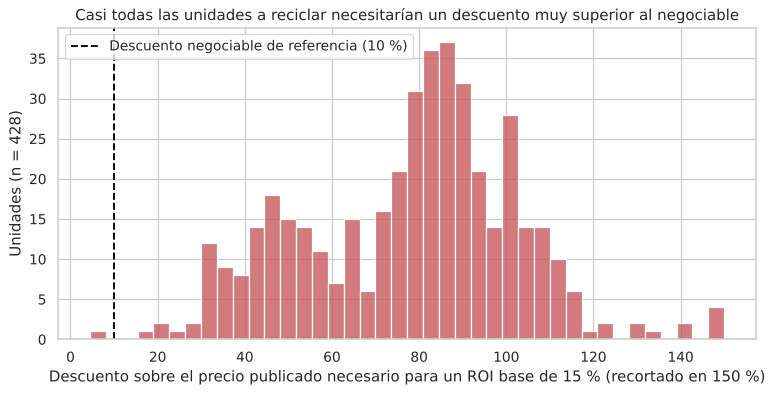

Unidades que alcanzarían el margen con un descuento ≤ 30 % (lista de seguimiento): 7


,Ranking_Priorizado,ID,Barrio_Oficial,Precio_Valor,Precio_Max_Oferta_Base_USD,Descuento_Requerido_Base_pct,Nivel_Obra,ROI_Optimista_pct,Cantidad_Alertas,Decision
0,1,550445,Palermo,99900.0,95410.6,4.5,Media,47.2,1,Revisar manualmente
1,2,391982,Palermo,63000.0,52248.6,17.1,Media,27.6,1,Descartar
2,3,647627,Recoleta,850000.0,687403.4,19.1,Media,38.4,4,Descartar
3,4,511218,Belgrano,249000.0,195784.5,21.4,Media,19.9,0,Descartar
4,5,633345,Palermo,56000.0,42413.1,24.3,Media,18.7,0,Descartar
5,6,588328,Palermo,70000.0,49596.5,29.1,Media,12.0,1,Descartar
6,7,619765,Belgrano,270000.0,189534.0,29.8,Media,6.9,0,Descartar


In [6]:
display(flip["Decision"].value_counts().to_frame("Unidades"))
display(flip["Robustez_Economica"].value_counts().to_frame("Unidades"))

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(flip["Descuento_Requerido_Base_pct"].clip(upper=150), bins=40, ax=ax, color="#C44E52")
ax.axvline(DESCUENTO_NEGOCIABLE_PCT, color="black", ls="--",
           label=f"Descuento negociable de referencia ({DESCUENTO_NEGOCIABLE_PCT} %)")
ax.set(title="Casi todas las unidades a reciclar necesitarían un descuento muy superior al negociable",
       xlabel=f"Descuento sobre el precio publicado necesario para un ROI base de {MARGEN_MINIMO_PCT} % (recortado en 150 %)",
       ylabel=f"Unidades (n = {len(flip)})")
ax.legend()
plt.show()

seg = flip[flip["Descuento_Requerido_Base_pct"] <= 30]
print("Unidades que alcanzarían el margen con un descuento ≤ 30 % (lista de seguimiento):", len(seg))
display(seg[["Ranking_Priorizado", "ID", "Barrio_Oficial", "Precio_Valor", "Precio_Max_Oferta_Base_USD",
             "Descuento_Requerido_Base_pct", "Nivel_Obra", "ROI_Optimista_pct", "Cantidad_Alertas",
             "Decision"]].round(1))

## 3. Recomendaciones

**Para la decisión 1 (qué visitar).**

1. Priorizar las candidatas de mayor confianza del ranking de visitas
   (`data/processed/ranking_visitas.csv`): son baratas por dos métodos
   independientes y no tienen indicadores de error de carga. El orden exacto
   dentro del ranking es sensible al método (solo 20 del top 50 coinciden con el
   orden por el otro gap), así que conviene usarlo por tramos (por ejemplo, las
   primeras 50) y no por puesto.
2. Actuar rápido: el 41 % de las candidatas de mayor confianza ya está reservada
   o en negociación, contra el 23 % de las no baratas. El mercado también las
   detecta, y eso es además evidencia de que la señal no es solo error de carga.
3. Antes de ofertar, verificar el aviso: superficie, estado, piso y situación
   legal. Los modelos no observan esas variables, y su error mediano ronda el 12 %.

**Para la decisión 2 (flipping).**

4. No adoptar el flipping de unidades a reciclar como estrategia general a
   precio publicado: con los costos con fuente, el descuento de entrada no paga
   la obra.
5. Usar el **precio máximo de oferta** como techo de negociación: ofertar ese
   valor y comprar solo si se acepta.
6. Antes de cualquier oferta, obtener una cotización de obra propia y una visita
   técnica: el alcance real de la obra es el supuesto que más mueve el resultado.

## 4. Limitaciones

- Precios de publicación, no de cierre, en una sola fuente (RE/MAX) y una sola
  captura.
- El estado de la propiedad se infiere del texto (validado manualmente sobre
  muestras, notebook 06).
- Los costos de obra son supuestos con fuente secundaria, no cotizaciones
  propias.
- Las recomendaciones priorizan qué investigar; no son una tasación individual.

## 5. Próximos pasos

- Capturas sucesivas para medir el tiempo de venta y validar que las baratas se
  venden antes.
- Cotizaciones reales por nivel de obra para recalibrar el modelo de flipping.
- Incorporar las fuentes externas complementarias (subte, espacios verdes) al
  benchmark ajustado.